<center><h1> ETI195 - Ética para Ciencia de Datos y Estadística </h1><center>
<center><h2> Taller Sumativo 3: Modelos interpretables y xAI <h2><center>  




# `Instrucciones generales`

Esta es la parte III del proyecto, considerá ultizar tus resultados anteriores
y reciclar el código anterior.

## `Temas formales`

**Modalidad**: Grupos de 3 personas.

**Formato de entrega:** El trabajo debe entregarse a través de Canvas, tanto en formato Jupyter ejecutable (.ipynb) como en formato PDF.

**Formalidades de las respuestas:**
- Citas: APA 7.
- Se espera buena ortografía y redacción, con respuestas en tono académico.
- No respondan con simples "si" o "no" , considera argumentar tu respuestas y justificar con bibliografía si lo estimas necesario.

## `Recomendaciones`

- Asistan a los talleres formativos, revisen los ejemplos de código y consulten sus dudas con sus ayudantes.

- **Lean la rúbrica antes de hacer su tarea.**

## `Integridad académica y uso de IA`

El uso de asistentes de IA sigue los lineamientos de integridad académica del curso, con las siguientes excepciones:

- Pueden usar IA para consultar por bugs y entender mejor el código.
- Pueden usar IA para generar las representaciones visuales que estimen convenientes.

Si tienen dudas sobre el uso de IA o la citación de código externo, no duden en preguntar. Pueden usar libremente los códigos de los talleres formativos. <3


In [1]:
# Coloque aquí todas las importaciones que considere necesarias.
from transformers import pipeline
from lime.lime_text import LimeTextExplainer
import numpy as np
import matplotlib.pyplot as plt

# Parte 1: Interpretabilidad local con LIME

## Motivación

Un modelo de clasificación de texto puede tener buen desempeño agregado y aun así fallar sistemáticamente ante ciertos tipos de lenguaje: eufemismos, tecnicismos, formas indirectas de comunicar una noticia, o lenguaje cargado políticamente. Estas fallas suelen ser invisibles si solo miramos métricas globales o si confiamos ciegamente en el sistema. LIME permite explorar una predicción individual y preguntar: ¿qué palabras llevaron al modelo a decidir esto? Esto es especialmente relevante cuando el texto que se clasifica admite múltiples interpretaciones, tiene una carga social relevante y, en definitiva, forma parte de un sistema con consecuencias reales sobre las personas.

En esta parte van a diseñar un pequeño experimento: eligen un contexto de riesgo asociado a su proyecto, construyen frases que pongan a prueba ese riesgo específico, y usan LIME para ver si el modelo efectivamente falla (o no) de la manera que hipotetizaron.

## Parte 1.1: Contexto

Lo primero que deben hacer es definir el contexto de su análisis. Dependiendo del proyecto que su grupo haya escogido, elijan un escenario en el que un sistema sociotécnico relacionado con su dataset tuviera que clasificar lenguaje, y en el que un error de clasificación tuviera una consecuencia concreta. Por ejemplo:

- **CIRI**: un sistema que clasifica declaraciones oficiales de gobiernos para detectar lenguaje que minimiza o niega violaciones a los derechos humanos.

- **Breast Cancer**: un sistema que analiza cómo se comunica un diagnóstico a pacientes.

- **CASEN**: un sistema que clasifica comunicaciones de resultados de ayudas sociales.

**Responder:**

0. Explica los conceptos clave: XAI, LIME y SHAP y lo que se busca hacer con estos en el contexto del taller.

1. Describan el escenario de riesgo que eligieron: ¿qué tipo de frases van a analizar y por qué esas frases son relevantes para ese escenario? Creen o recopilen al menos 10 frases.

## Parte 1.2: Aplicación de LIME

1. Carguen el modelo BETO de análisis de sentimientos.

2. Obtengan la predicción del modelo para cada frase y comparen los resultados con su hipótesis de 1.1: ¿se cumplió lo que esperaban?

3. Apliquen LIME para obtener la explicación local de al menos 5 frases, priorizando aquellas donde el modelo se comportó de forma inesperada o donde identifiquen un problema ético. Si no encuentran ningún problema, justifiquen esa conclusión. Para cada una, visualicen las contribuciones de cada palabra mediante un gráfico de barras.

4. Interpreten los resultados: ¿qué palabras están dominando cada predicción? ¿El modelo se apoya en las palabras que ustedes esperaban, o en otras? ¿Identifican un problema ético o social en los resultados?

# Respuestas

## Parte 1.1.

### Conceptos clave

Explica los conceptos clave: XAI, LIME y SHAP y lo que se busca hacer con estos en el contexto del taller.

**XAI:** (Explainable Artificial Intelligence). La inteligencia artificial explicable es un concepto general que agrupa técnicas y métodos que buscan explicar cómo funcionan los modelos de inteligencia artificial y por qué producen determinadas predicciones. Su objetivo es comprender mejor las decisiones del modelo y evaluar si estas tienen sentido (IBM, 2026).

**LIME:** (Local Interpretable Model-agnostic Explanations). Es una técnica que permite explicar predicciones individuales mediante la aproximación local del comportamiento de un modelo complejo, utilizando un modelo más sencillo e interpretable. En la clasificación de texto, permite identificar qué palabras influyeron en una predicción específica y cómo contribuyeron al resultado obtenido.

**SHAP:** (SHapley Additive exPlanations). Es un método que permite comprender cómo un modelo de aprendizaje automático realiza sus predicciones, estimando cuánto contribuye cada característica al resultado. En la clasificación de texto, puede ayudar a identificar qué palabras influyeron positiva o negativamente en la predicción de una categoría (GeeksforGeeks, 2025).

En nuestro caso, donde trabajaremos con un sistema que analiza cómo se comunica un diagnóstico a los pacientes, el objetivo es ir más allá de construir un modelo de clasificación de texto. Se busca comprender qué elementos del lenguaje influyen en las predicciones y por qué el modelo asigna un mensaje a una determinada categoría.

Para esto, XAI proporciona la explicabilidad, mientras que LIME y SHAP permiten analizar las predicciones del modelo desde distintas perspectivas. De esta forma, podremos identificar qué palabras o características influyen en los resultados, detectar posibles errores y evaluar si el modelo se basa en elementos relevantes del mensaje. Sin embargo, estas explicaciones muestran cómo se comporta el modelo y no garantizan que sus decisiones sean correctas (IBM, 2026; GeeksforGeeks, 2025).

### Escenario escogido

1. Describan el escenario de riesgo que eligieron: ¿qué tipo de frases van a analizar y por qué esas frases son relevantes para ese escenario? Creen o recopilen al menos 10 frases.

**Escenario:** El sistema analizará frases utilizadas para comunicar un diagnóstico de cáncer de mama, con el objetivo de estudiar si la comunicación presenta características que podrían dificultar la comprensión de los pacientes, transmitir información de forma poco empática o generar confusión.

Para estudiar este escenario, nos basaremos en cinco criterios de comunicación que nos permitirán formular frases más precisas para evaluar el funcionamiento del modelo. Cabe destacar que estos criterios fueron obtenidos de la página **Sermo**, la cual destaca la importancia de la comunicación entre el médico y el paciente. Además, aborda los problemas que pueden surgir cuando esta comunicación es deficiente, como las experiencias de pacientes que se sienten ignorados, juzgados o tratados con falta de respeto. Estos aspectos son relevantes para nuestro trabajo, ya que buscamos analizar cómo la forma de comunicar un diagnóstico puede influir en la comprensión y la experiencia del paciente (Team, 2025).

**Criterios:**

1. **Utilizar un lenguaje sencillo:** Permite analizar si el diagnóstico se comunica con palabras comprensibles para el paciente, evitando tecnicismos innecesarios (Team, 2025).

2. **Prestar atención al paciente:** Permite identificar expresiones que demuestran disposición a escuchar, resolver dudas y considerar las inquietudes del paciente (Team, 2025).

3. **Ser honesto y realista:** Permite analizar si el mensaje comunica la situación con claridad, sin prometer resultados inciertos ni minimizar la gravedad del diagnóstico (Team, 2025).

4. **Dar instrucciones y consejos personalizados y aplicables:** Permite examinar si el mensaje proporciona pasos concretos y pertinentes para que el paciente comprenda qué puede hacer a continuación (Team, 2025).

5. **Ser organizado y conciso:** Permite evaluar si el mensaje presenta la información de manera ordenada y directa, evitando expresiones innecesariamente confusas (Team, 2025).

**Frases:**

Frases propuestas

1. Los resultados confirman que tiene cáncer de mama. Entiendo que esta noticia puede ser difícil, por eso quiero explicarle con calma qué significa y cuáles son los siguientes pasos.

2. La biopsia mostró células cancerosas en el tejido mamario. Necesitamos revisar el tipo de tumor y determinar qué tratamiento podría ser el más adecuado para usted.

3. El diagnóstico corresponde a un carcinoma mamario invasivo con características histopatológicas que requieren una evaluación adicional para establecer el estado de la enfermedad.

4. Su tumor presenta receptores hormonales positivos y debemos evaluar si la hormonoterapia podría ser una alternativa dentro de su tratamiento.

5. Los resultados muestran una neoplasia maligna con un perfil inmunohistoquímico específico. Debemos correlacionar estos hallazgos con los estudios de imagen para definir la conducta terapéutica.

6. Ya le expliqué los resultados de la biopsia. Debería entender lo que significa y no es necesario que volvamos a revisar la misma información.

7. Los resultados muestran una alteración que debemos estudiar con más detalle. Le explicaré qué significa y qué exámenes necesitamos realizar a continuación.

8. Su diagnóstico es complicado y hay muchas cosas que debe saber, pero ahora no tenemos tiempo para explicarle todo.

9. Debe seguir las indicaciones del tratamiento y asistir a sus controles. Si tiene dudas sobre los medicamentos o presenta molestias, puede consultarnos.

10. El resultado no es bueno. Tiene que aceptar la situación y esperar a ver qué pasa, porque no hay mucho más que podamos hacer por ahora.

Estas frases fueron elaboradas en base a los puntos explicados anteriormente, dando mayor énfasis al uso del lenguaje técnico, la claridad de la información y la empatía hacia el paciente. Aunque algunos términos médicos sean correctos, pueden resultar difíciles de comprender o generar preocupación en las personas (Team, 2025).

Además, las frases fueron construidas con distintas formas de comunicar un diagnóstico, desde mensajes claros y empáticos hacia el paciente hasta otros que utilizan tecnicismos o que pueden transmitir preocupación. Esto nos permitirá utilizarlas como ejemplos para un modelo de clasificación de texto, con el objetivo de distinguir entre una comunicación potencialmente adecuada y otra potencialmente problemática.

## Parte 1.2.

    1. Cargara modelo BETO

El modelo BETO como se explico en la ayudantia es un modelo entrenado sobre un corpus masivo de texto en español. Es un modelo tipo trasnformer el cual puede utilizarse para disintas tareas de porcesamiento de lenguaje natural, como en nuestro caso clasificación de texto.

In [2]:
# Cargamos el modelo

modelo_beto = pipeline(
    "text-classification",
    model="vipont/beto-sentiment-spanish",
    top_k=None
)



Device set to use cpu


    2. Predicciones del modelo y comparación con la hipótesis

In [3]:
import pandas as pd

frases = [
    "Los resultados confirman que tiene cáncer de mama. Entiendo que esta noticia puede ser difícil, por eso quiero explicarle con calma qué significa y cuáles son los siguientes pasos.",
    "La biopsia mostró células cancerosas en el tejido mamario. Necesitamos revisar el tipo de tumor y determinar qué tratamiento podría ser el más adecuado para usted.",
    "El diagnóstico corresponde a un carcinoma mamario invasivo con características histopatológicas que requieren una evaluación adicional para establecer el estado de la enfermedad.",
    "Su tumor presenta receptores hormonales positivos y debemos evaluar si la hormonoterapia podría ser una alternativa dentro de su tratamiento.",
    "Los resultados muestran una neoplasia maligna con un perfil inmunohistoquímico específico. Debemos correlacionar estos hallazgos con los estudios de imagen para definir la conducta terapéutica.",
    "Ya le expliqué los resultados de la biopsia. Debería entender lo que significa y no es necesario que volvamos a revisar la misma información.",
    "Los resultados muestran una alteración que debemos estudiar con más detalle. Le explicaré qué significa y qué exámenes necesitamos realizar a continuación.",
    "Su diagnóstico es complicado y hay muchas cosas que debe saber, pero ahora no tenemos tiempo para explicarle todo.",
    "Debe seguir las indicaciones del tratamiento y asistir a sus controles. Si tiene dudas sobre los medicamentos o presenta molestias, puede consultarnos.",
    "El resultado no es bueno. Tiene que aceptar la situación y esperar a ver qué pasa, porque no hay mucho más que podamos hacer por ahora.",
]

# Etiquetas que usa el modelo (ordenadas por índice)
id2label = modelo_beto.model.config.id2label
class_names = [id2label[i] for i in sorted(id2label)]
print(class_names)

['LABEL_0', 'LABEL_1']


In [4]:
filas = []
for i, f in enumerate(frases, 1):
    salida = modelo_beto(f, truncation=True)[0]   # lista de {label, score}
    fila = {"frase": i}
    fila.update({d["label"]: round(d["score"], 3) for d in salida})
    fila["pred"] = max(salida, key=lambda d: d["score"])["label"]
    filas.append(fila)

df_pred = pd.DataFrame(filas)
df_pred

,frase,LABEL_1,LABEL_0,pred
0,1,0.969,0.031,LABEL_1
1,2,0.789,0.211,LABEL_1
2,3,0.440,0.560,LABEL_0
3,4,0.463,0.537,LABEL_0
4,5,0.583,0.417,LABEL_1
5,6,0.842,0.158,LABEL_1
6,7,0.633,0.367,LABEL_1
7,8,0.938,0.062,LABEL_1
8,9,0.984,0.016,LABEL_1
9,10,0.010,0.990,LABEL_0


**Hipótesis:** esperábamos que el modelo asignara una clase negativa a las frases frías o poco empáticas (6, 8 y 10) y a las que usan un lenguaje muy técnico (3 y 5), y una clase positiva a las frases empáticas, claras y orientadas a la acción (1, 7 y 9). Si había un problema ético, esperábamos que se manifestara en que el modelo reacciona al vocabulario y no a la calidad comunicativa del mensaje.

*Nota sobre las etiquetas: el modelo devuelve `LABEL_0` y `LABEL_1` sin nombre. Interpretamos `LABEL_0` como sentimiento negativo y `LABEL_1` como positivo, porque palabras como "maligna" o "no" empujan hacia `LABEL_0` en los gráficos de LIME.*

**¿Se cumplió?** Solo en parte.

- **Se cumplió** en las frases 1, 7 y 9 (positivas, con probabilidades de 0,97, 0,63 y 0,98), en la frase 3 (técnica, negativa con 0,61) y en la frase 10 (la más fría y fatalista, negativa con 0,99).
- **No se cumplió** en la frase 8 ("ahora no tenemos tiempo para explicarle todo"), clasificada como positiva con 0,94, ni en la frase 6 (condescendiente), positiva con 0,84. Tampoco en la frase 5 (técnica, con "neoplasia maligna"), positiva con 0,58.
- La frase 4 quedó cerca del límite (0,54 negativa), lo que indica poca seguridad del modelo.

El modelo distingue bien el caso más extremo (frase 10), pero no detecta la falta de empatía cuando esta se expresa con un lenguaje cortés o formal.

    3. Aplicación de LIME

Aplicamos LIME a las frases donde el modelo se comportó de forma inesperada o donde identificamos un posible problema ético. En verde se muestran las palabras que empujan hacia la clase predicha y en rojo las que van en contra.

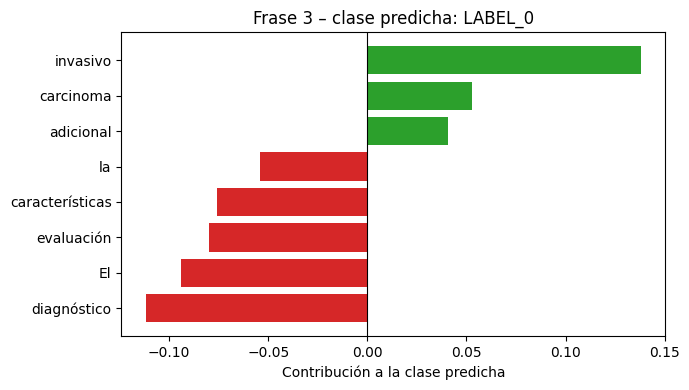

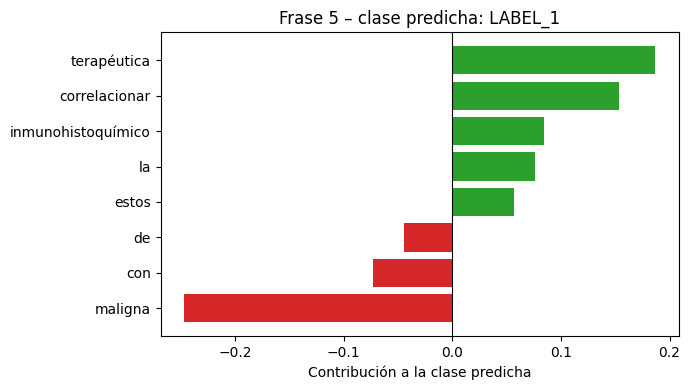

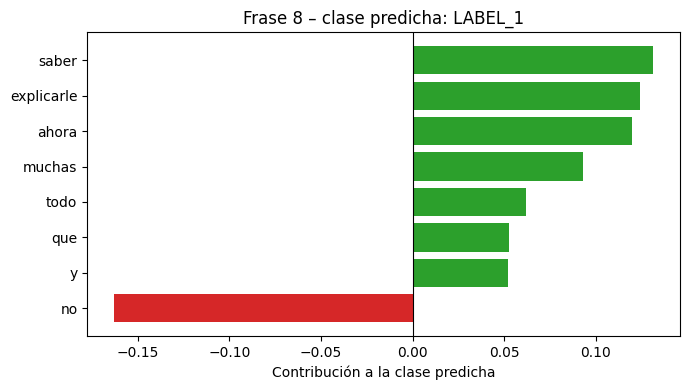

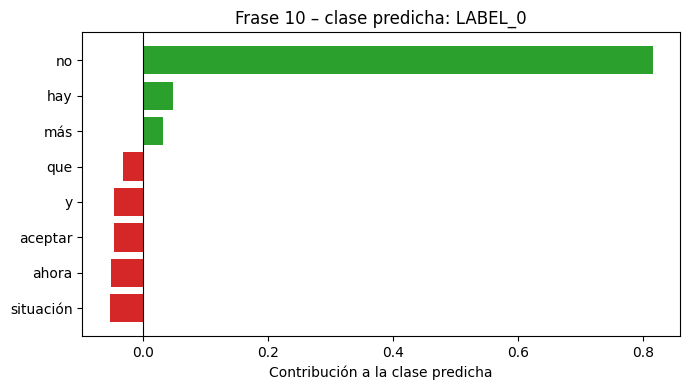

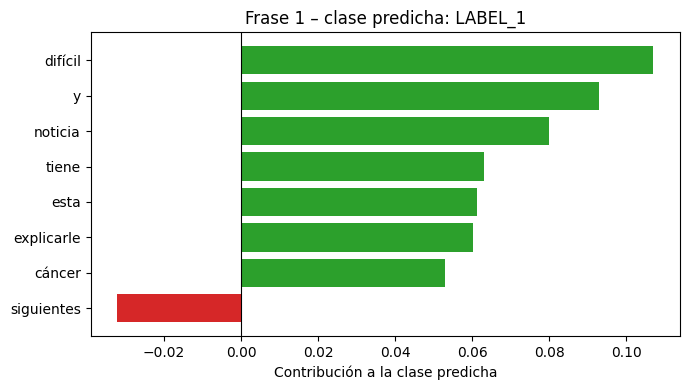

In [5]:
def predict_proba(textos):
    salidas = modelo_beto(list(textos), truncation=True, batch_size=16)
    probs = []
    for s in salidas:
        d = {x["label"]: x["score"] for x in s}
        probs.append([d[c] for c in class_names])
    return np.array(probs)

explainer = LimeTextExplainer(class_names=class_names)

def explicar(idx, num_features=8, num_samples=500):
    """idx: número de frase (1-10). Grafica los pesos LIME para la clase predicha."""
    texto = frases[idx - 1]
    clase = int(np.argmax(predict_proba([texto])[0]))
    exp = explainer.explain_instance(
        texto, predict_proba,
        num_features=num_features, num_samples=num_samples, labels=[clase]
    )
    pares = sorted(exp.as_list(label=clase), key=lambda p: p[1])
    palabras, pesos = zip(*pares)
    colores = ["tab:red" if p < 0 else "tab:green" for p in pesos]

    plt.figure(figsize=(7, 4))
    plt.barh(palabras, pesos, color=colores)
    plt.axvline(0, color="k", lw=0.8)
    plt.title(f"Frase {idx} – clase predicha: {class_names[clase]}")
    plt.xlabel("Contribución a la clase predicha")
    plt.tight_layout()
    plt.show()
    return exp

# Ajustar la lista según las frases más interesantes de df_pred
for i in [3, 5, 8, 10, 1]:
    explicar(i)

#### Interpretación de los resultados

**Qué palabras dominan cada predicción**

- **Frase 3 (negativa):** "invasivo" y "carcinoma" son las que más empujan hacia la clase negativa. Palabras de relleno como "El", "la" o "diagnóstico" van en contra. El modelo reacciona al vocabulario médico de gravedad, no a que la frase sea difícil de entender para un paciente.
- **Frase 5 (positiva):** "maligna" tiene el mayor peso y va claramente en contra de la clase positiva (cerca de -0,3). Sin embargo, términos técnicos neutros como "terapéutica", "correlacionar", "definir" o "inmunohistoquímico" suman a favor de la clase positiva y compensan ese efecto. La jerga técnica diluye la señal negativa y el mensaje termina clasificado como positivo.
- **Frase 8 (positiva):** las palabras que más aportan a la clase positiva son "saber", "explicarle", "muchas" y "ahora". El modelo se apoya en verbos de comunicación que en otro contexto serían empáticos. La palabra "no" se opone a la clase positiva, pero no alcanza a compensar. La negativa a explicar el diagnóstico pasa inadvertida.
- **Frase 10 (negativa):** la palabra "no" concentra casi toda la predicción (cerca de 0,8). El modelo clasifica la frase como negativa por la presencia de la negación, no por el fatalismo ni por la renuncia a acompañar al paciente.
- **Frase 1 (positiva):** "difícil", "noticia" y "cáncer" aparecen entre las palabras que *favorecen* la clase positiva, junto con "Entiendo" y "explicarle". Es contraintuitivo, y probablemente el modelo no trata esas palabras como negativas porque aparecen en una construcción empática.

**¿Se apoya en las palabras esperadas?** Solo a veces. Esperábamos que los marcadores de empatía ("Entiendo", "con calma") y de frialdad ("no tenemos tiempo", "Tiene que aceptar") guiaran la decisión. En la práctica pesan más la negación "no", el vocabulario médico de gravedad ("maligna", "invasivo") y verbos de comunicación como "explicarle". Además, LIME es una aproximación local y estocástica, por lo que los pesos pueden variar entre ejecuciones y deben leerse como tendencias, no como valores exactos.

**Problema ético y social**

1. **El modelo mide tono léxico, no calidad comunicativa.** Un modelo de sentimiento fue entrenado para detectar opiniones positivas o negativas, no para evaluar si un diagnóstico se comunicó con claridad, honestidad y respeto (los criterios que definimos en 1.1). Usarlo para ese fin sería un error de validez.
2. **Falsos "aprobados".** Las frases 8 y 6 comunican desinterés o impaciencia, y el modelo las clasifica como positivas. Un sistema que supervisara la comunicación médica con esta herramienta dejaría pasar justo los mensajes que más dañan la experiencia del paciente.
3. **Falsos "reprobados".** Mensajes honestos que mencionan términos graves ("maligna", "invasivo") o usan negaciones necesarias pueden ser penalizados. Eso incentivaría a suavizar o evitar información veraz, lo contrario del criterio de ser honesto y realista.
4. **Sesgo por jerga.** La frase 5, llena de tecnicismos y por tanto menos comprensible, obtiene una clasificación positiva. El modelo no penaliza la opacidad del lenguaje, lo que es un problema de equidad: los pacientes con menos formación en salud son quienes más dependen de una comunicación clara.
5. **Límite de LIME.** La explicación muestra en qué palabras se apoya el modelo, pero no garantiza que la decisión sea correcta ni justa. Sirve para detectar que el modelo acierta o falla "por la razón equivocada", por lo que no debería usarse sin supervisión humana en un contexto con consecuencias reales.

# Parte 2 : Explicabilidad de Random Forest con SHAP


En esta segunda parte del taller continuarán el trabajo anterior. Usando la limpieza y estandarización que ya realizaron, entrenen ahora un modelo Random Forest. Recuerden que, como mínimo, en la parte anterior debieron haber realizado los siguientes pasos:

2.1 Carga y limpieza de datos

- Revisión de qué columnas tienen nulos o datos faltantes y manejo de estos mediante: 0, botar fila/columna, o imputación de media.

- Revisión del tipo de dato del dataset y de los cambios realizados, si corresponde.

- Codificación de las variables categóricas, ya sea con label encoder, one-hot encoder, dummies, o mapeo manual en caso de columnas binarias.


## `Librerias`

In [6]:
import pandas as pd
import numpy as np
import shap
import funciones_limpieza as fl
import matplotlib.pyplot as plt

from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import train_test_split
from sklearn.metrics import confusion_matrix, accuracy_score, ConfusionMatrixDisplay, classification_report
from sklearn.preprocessing import LabelEncoder, OneHotEncoder, StandardScaler,MinMaxScaler


2.2 División del conjunto de datos
- separe del conjunto total los predictores y **la variable objetivo **
- Utilice train_test_split para obtener el conjunto de prueba y entrenamiento.

(La variable objetivo no difiere de la utilizada en el taller anterior)



2.3 Estandarización
- Estandarice los datos numéricos con StandarScaler o Minmax
- Justifique brevemente su elección






2.4 Clasificador Random Forest y métrica de evaluación
- Entrenen un Random Forest, seleccionen un número de estimadores y entreguen las predicciones del modelo.
- Comenten los resultados de la matriz de confusión y del reporte de clasificación. Expliquen las consecuencias de aplicar ese modelo específico en el área que abarca su proyecto.

2.5 Resultado y explicaciones con SHAP
- Comenta los beneficios y perjuicios que puede tener una herramienta como SHAP, en general y aterriza al caso de los datos trabajados
- Obten los valores shap.Visualiza el summary plot. Comenta los resultados.
- Analiza que features son importantes para la predicción y que puede influir en que estas tengan mayor influencia. Considera en tu explicación la relevancia de los resultados en el contexto.

- Preguntas guía para tu respuesta : ¿Qué aporta conocer los valores SHAP? ¿Es una herramienta suficiente en sí misma o puede apoyarse con otras? ¿Cómo afecta la preparación de los datos a las predicciones y su posterior explicación? ¿Es importante tener acceso a ambas interpretaciónes (global y local) en este caso?

## Parte 2

### 2.1
Primero importamos la base de datos con la limpieza ya realizada 

In [2]:
df = fl.limpiar_datos("breast_cancer_prediction.csv")

### 2.2

In [3]:
X = df.drop("Cancer", axis=1)
y = df["Cancer"]

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

print(X_train.shape, X_test.shape)

(7760, 23) (1940, 23)


### 2.3
Justificación: Las variables numéricas se estandarizaron con StandardScaler en la función de limpieza del Taller 2. 
Se eligió este método ya que las variables tienen escalas muy distintas(la edad es de un rango de 20 a 84 años y el ingreso anual de 15.00 a 150.000), por lo que ninguna va a pesar más solo por la magnitud de sus valores.

In [4]:
df[["Age", "BMI", "Tumor_Size_cm", "Annual_Income_USD"]].describe().round(2)

,Age,BMI,Tumor_Size_cm,Annual_Income_USD
count,9700.00,9700.00,9700.00,9700.00
mean,-0.00,-0.00,0.00,0.00
std,1.00,1.00,1.00,1.00
min,-1.71,-2.73,-1.66,-1.72
25%,-0.85,-0.68,-0.80,-0.87
50%,-0.00,-0.01,-0.07,-0.02
75%,0.85,0.68,0.69,0.86
max,1.70,2.73,2.92,1.73


### 2.4

Accuracy: 0.9644329896907217
              precision    recall  f1-score   support

           0      0.958     1.000     0.978      1563
           1      1.000     0.817     0.899       377

    accuracy                          0.964      1940
   macro avg      0.979     0.908     0.939      1940
weighted avg      0.966     0.964     0.963      1940



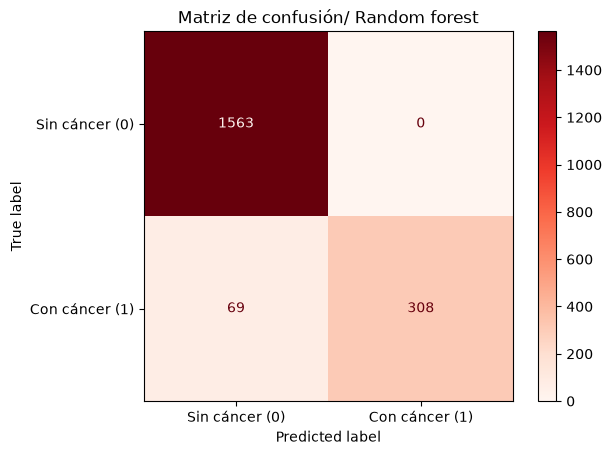

In [7]:
rf = RandomForestClassifier(n_estimators=200, class_weight="balanced", random_state=42,n_jobs=1)
rf.fit(X_train, y_train)
y_pred = rf.predict(X_test)
print("Accuracy:", accuracy_score(y_test, y_pred))
print(classification_report(y_test, y_pred, digits=3))

cm = confusion_matrix(y_test, y_pred)
ConfusionMatrixDisplay(cm, display_labels=["Sin cáncer (0)", "Con cáncer (1)"]).plot(cmap="Reds", values_format="d")
plt.title("Matriz de confusión/ Random forest")
plt.show()

Podemos notar que el modelo alcanzó un accuracy de 96,44% sobre los 1940 pacientes, esto nos da a entender que el accuracy alto puede tener errores asimétricos.
La matriz de confusión nos muestra 1563 verdaderos negativos, 308 verdaderos positivos, 69 falsos negativos y ningún falso positivo, en el contexto de quie si estos diagonsticos realmente existieran esto sería un error muy grave ya que pacientes que si presentan cáncer el modelo les indicaría que no lo tienen, lo que puede significar diagnosticos tardíos. No existen falsos positivos lo cual es bueno ya que no hay diagnosticos falsos, pero es el costo de dejar pasar casos reales.

### 2.5

**Beneficios y perjuicios de SHAP**

SHAP es una herramienta que muestra cuánto aporta cada variable a la predicción del modelo, y si la aumenta o la disminuye (Lundberg & Lee, 2017). El beneficio es que nos permite entender por qué el Random Forest decide lo que decide, tanto en general como para un paciente en específico. En nuestro caso, esto nos sirve para revisar si el modelo usa variables con sentido clínico (tamaño del tumor, mamografía, mutación genética) y no variables como el ingreso o el género.

Como perjuicio, SHAP explica el modelo y no la realidad, que una variable sea importante no significa que cause cáncer. Además, como nuestras variables están estandarizadas, los valores no aparecen en centímetros o años, lo que hace más difícil interpretarlos. Por último, el dataset es sintético, entonces SHAP muestra cómo se generaron los datos pero eso no asegura que pase lo mismo con pacientes reales.

In [8]:
explainer = shap.TreeExplainer(rf)
shap_values = explainer(X_test)

# nos quedamos con la clase 1 = con cancer
sv = shap_values[:, :, 1]

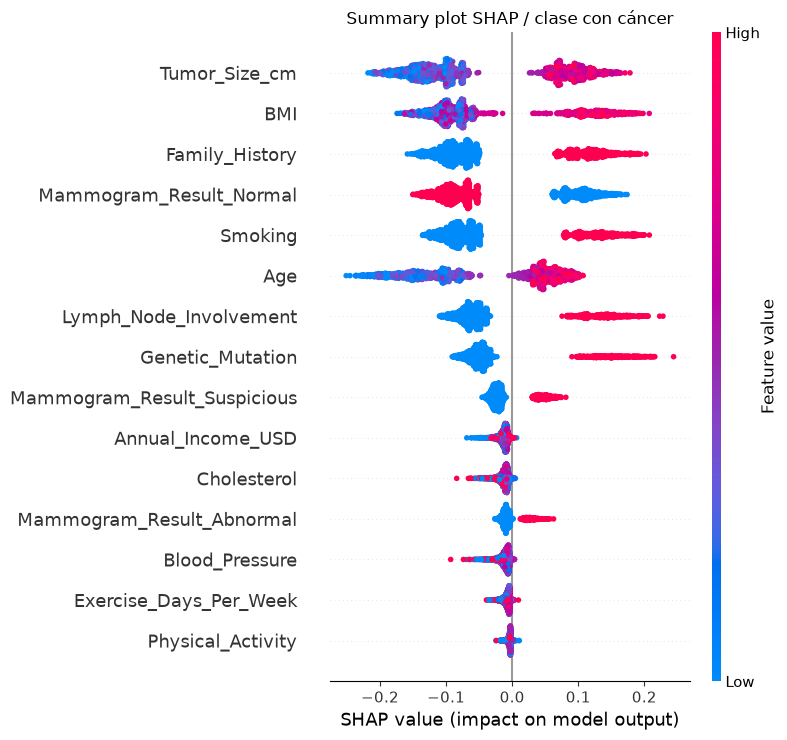

In [9]:
shap.summary_plot(sv.values, X_test, max_display=15, show=False)
plt.title("Summary plot SHAP / clase con cáncer")
plt.tight_layout()
plt.show()

**Comentario del summary plot**

Cada punto es un paciente. Si está a la derecha, esa variable aumentó la probabilidad de cáncer, y si está a la izquierda la disminuyó. El color rojo indica un valor alto y el azul uno bajo.

Podemos notar que las variables más importantes son el tamaño del tumor, el IMC, los antecedentes familiares, la mamografía normal, fumar, la edad, los ganglios comprometidos y la mutación genética. Todas van en la dirección esperada, por ejemplo un tumor más grande o tener la mutación aumentan la probabilidad, mientras que una mamografía normal la disminuye. En cambio, el ingreso, el colesterol y la presión casi no influyen, y el género ni siquiera aparece entre las 15 variables más importantes, lo cual es bueno porque el modelo no estaría discriminando por esas variables.

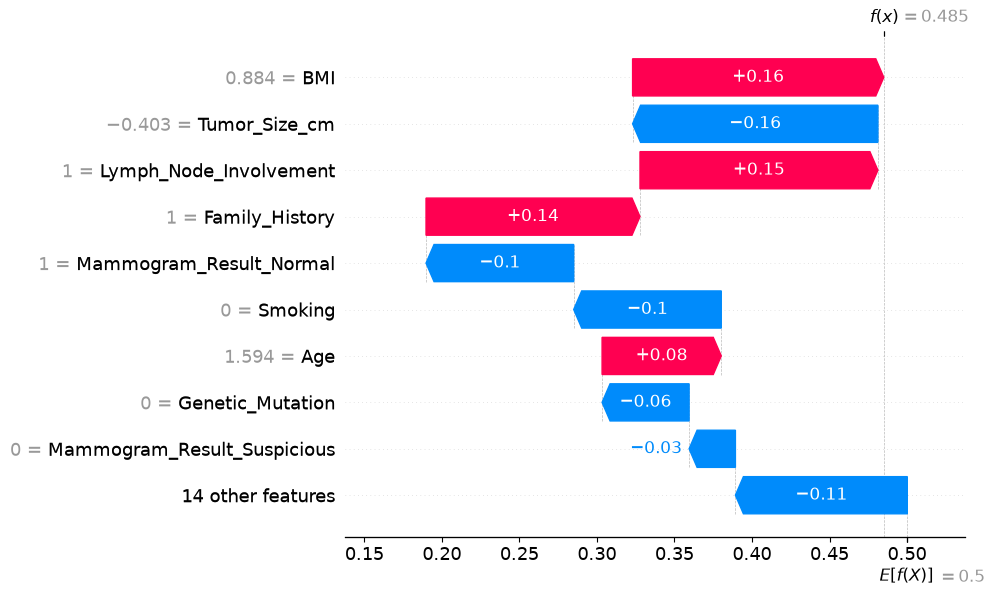

In [10]:
# revisamos un falso negativo (tenia cancer pero el modelo dijo que no)
falsos_neg = np.where((y_test.values == 1) & (y_pred == 0))[0]
i = falsos_neg[0]
shap.plots.waterfall(sv[i], max_display=10)

En este falso negativo el modelo le asignó una probabilidad de 0,485, quedando muy cerca del umbral de 0,5. La paciente tenía factores que aumentan la probabilidad, como el IMC alto, los ganglios comprometidos, los antecedentes familiares y la edad, pero estos se compensaron con otros que la bajan, principalmente un tumor pequeño, una mamografía normal, no fumar y no tener la mutación genética. Esto nos muestra que el modelo puede fallar con pacientes que tienen algunos factores de riesgo importantes, como los ganglios comprometidos, pero no tienen el perfil típico. Además, en la realidad una mamografía normal o un tumor pequeño no descartan el cáncer, por lo que en casos tan cerca del umbral sería importante que un médico los revise.

In [11]:
# importancia promedio de cada variable
importancia = pd.Series(np.abs(sv.values).mean(axis=0), index=X_test.columns).sort_values(ascending=False)
print(importancia.head(8).round(3))

# sumamos las 3 columnas de mamografia para ver su importancia como una sola variable
mamo = [c for c in X_test.columns if "Mammogram" in c]
shap_df = pd.DataFrame(sv.values, columns=X_test.columns)
print("Mamografía (las 3 columnas juntas):", round(shap_df[mamo].sum(axis=1).abs().mean(), 3))

Tumor_Size_cm              0.111
BMI                        0.103
Family_History             0.097
Mammogram_Result_Normal    0.095
Smoking                    0.094
Age                        0.091
Lymph_Node_Involvement     0.078
Genetic_Mutation           0.066
dtype: float64
Mamografía (las 3 columnas juntas): 0.129


**Análisis de las variables importantes**

Las variables más importantes son el tamaño del tumor, el IMC, los antecedentes familiares, la mamografía, fumar, la edad, los ganglios comprometidos y la mutación genética. Esto tiene sentido en el contexto, ya que son factores de riesgo conocidos del cáncer de mama, y es positivo que el modelo no se apoye en variables como el ingreso.

Sin embargo, hay cosas que influyen en que estas variables pesen más. Primero, el dataset es sintético, por eso variables como el IMC o fumar pesan casi lo mismo que el tamaño del tumor, lo que en la realidad probablemente no sería así. Segundo, al usar dummies la mamografía quedó dividida en tres columnas y su importancia se repartió, por eso en el gráfico la columna Normal aparece en el cuarto lugar y las otras dos más abajo. Pero si sumamos las tres columnas su importancia llega a 0,129, superando al tamaño del tumor (0,111), por lo que en realidad es la variable más importante del modelo. Tercero, al eliminar Biopsy_Result y Cancer_Stage evitamos que el modelo usara variables que casi contienen la respuesta.

En el contexto de un diagnóstico esto es relevante, porque si el modelo le da tanto peso a la mamografía, los pacientes con mamografía normal pero con cáncer pueden quedar como falsos negativos, como vimos en el caso anterior.

**Preguntas guía**

**¿Qué aporta conocer los valores SHAP?** Nos permite entender por qué el modelo predice lo que predice, revisar si usa variables con sentido y ver en qué casos se equivoca.

**¿Es suficiente por sí sola?** No, SHAP muestra cómo funciona el modelo pero no si es correcto o justo. Se puede complementar con LIME (como en la parte 1), con métricas por grupo y con la opinión de médicos. Rudin (2019) incluso plantea que en decisiones de alto riesgo es mejor usar modelos interpretables desde el inicio.

**¿Cómo afecta la preparación de los datos?** Bastante, como vimos en el análisis anterior con las dummies y las columnas eliminadas. Además, al borrar las 300 filas con datos vacíos, si esos datos faltaban por alguna razón (por ejemplo, menos acceso a exámenes) esas personas quedan fuera del modelo. La estandarización no cambia las predicciones del Random Forest, porque los árboles solo comparan si un valor es mayor o menor que otro, pero sí hace más difícil interpretar los resultados, ya que los valores quedan en desviaciones estándar y no en centímetros o años.

**¿Es importante tener la interpretación global y local?** Sí, la global sirve para revisar el modelo en general y la local para entender casos específicos, como el falso negativo, que es el error más grave en este contexto.

**Referencias**

- Lundberg, S. M., & Lee, S.-I. (2017). A unified approach to interpreting model predictions. *Advances in Neural Information Processing Systems, 30*, 4765–4774. https://papers.nips.cc/paper/7062-a-unified-approach-to-interpreting-model-predictions

- Rudin, C. (2019). Stop explaining black box machine learning models for high stakes decisions and use interpretable models instead. *Nature Machine Intelligence, 1*(5), 206–215. https://doi.org/10.1038/s42256-019-0048-x

- GeeksforGeeks. (2025, 14 de julio). SHAP: A comprehensive guide to SHapley Additive exPlanations. https://www.geeksforgeeks.org/machine-learning/shap-a-comprehensive-guide-to-shapley-additive-explanations/

- IBM. (2026, 16 de agosto). ¿Qué es la IA explicable (XAI)? https://www.ibm.com/mx-es/think/topics/explainable-ai

- Team, S. (2025, 28 de octubre). La comunicación centrada en el paciente: 9 consejos para las conversaciones con los pacientes. Sermo. https://www.sermo.com/es/resources/la-comunicacion-centrada-en-el-paciente-9-consejos-para-las-conversaciones-con-los-pacientes/

- Ribeiro, M. T., Singh, S., & Guestrin, C. (2016). "Why should I trust you?": Explaining the predictions of any classifier. *Proceedings of the 22nd ACM SIGKDD International Conference on Knowledge Discovery and Data Mining*, 1135–1144. https://doi.org/10.1145/2939672.2939778

- Lundberg, S. M., & Lee, S.-I. (2017). A unified approach to interpreting model predictions. *Advances in Neural Information Processing Systems, 30*.